# Précipitations et mousson au Kerala (1901–2018)

**Projet IBI** — Ilan Aliouchouche, Marwan Khairallah et Youssef Mir

<img src="../assets/img/projet_ibi.jpg" alt="Paysage du Kerala" width="420">

> **En bref.** La mousson du sud-ouest (juin–septembre) apporte 69 % de la pluie annuelle du
> Kerala. De 1901 à 2017, le total annuel baisse d'environ 30 mm par décennie (pente de Sen,
> test de Mann-Kendall significatif), sans que la variabilité d'une année à l'autre augmente de
> façon démontrable. En août 2018, l'État reçoit pourtant près du double de la normale : un
> épisode extrême mais pas inédit à l'échelle du mois, dont le bilan humain dépend autant de
> l'exposition des territoires que de la pluie elle-même.

**Plan**

1. [Introduction](#1.-Introduction)
2. [Comment évoluent les précipitations annuelles ?](#2.-Comment-évoluent-les-précipitations-annuelles-?)
3. [La mousson : saisonnalité, tendance et variabilité](#3.-La-mousson-:-saisonnalité,-tendance-et-variabilité)
4. [Un événement extrême : les inondations d'août 2018](#4.-Un-événement-extrême-:-les-inondations-d'août-2018)
5. [L'évolution des températures en Inde](#5.-L'évolution-des-températures-en-Inde)
6. [Et l'agriculture ?](#6.-Et-l'agriculture-?)
7. [Le climat, seul responsable ?](#7.-Le-climat,-seul-responsable-?)
8. [Conclusion et limites](#8.-Conclusion-et-limites)

## 1. Introduction

Dans le cadre de notre projet de bio-informatique sur le réchauffement climatique, nous avons
cherché une région du monde à la fois belle et riche en données. Nous avons choisi l'État du
**Kerala**, au sud-ouest de l'Inde.

<img src="../assets/img/position_kerala.jpg" alt="Position du Kerala en Inde" width="220">

**Qu'est-ce que le Kerala ?** Un État côtier de 38 863 km² entre la mer d'Arabie et les Ghats
occidentaux, connu pour ses paysages verdoyants, ses backwaters, ses plantations d'épices, de
thé, de caoutchouc et de cocotiers. Le tourisme y est un secteur clé, et l'État est l'un des plus
développés de l'Inde (éducation, santé, services).

**Pourquoi le Kerala ?** Ses précipitations, presque entièrement apportées par la mousson,
conditionnent l'agriculture, l'économie et la vie de millions d'habitants. Le Kerala est
directement exposé au changement climatique, comme l'ont rappelé les inondations meurtrières
d'août 2018.

**La tâche.** Nous étudions l'évolution des précipitations du Kerala (tendance, saisonnalité,
variabilité), un événement extrême (août 2018), l'évolution des températures en Inde et
l'occupation des sols. L'objectif est aussi méthodologique : choisir des tests statistiques
adaptés à des séries climatiques et présenter des résultats rigoureux et lisibles.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from kerala_rain import data, plotting, stats
from kerala_rain.geo import area_weighted_mean, district_table

%matplotlib inline
plotting.use_style()


def show(table: pd.DataFrame, digits: int | dict = 1) -> None:
    # Affiche un tableau de résultats : p-valeurs lisibles, puis arrondi des autres colonnes.
    table = table.copy()
    if "p-valeur" in table:
        table["p-valeur"] = table["p-valeur"].map(stats.format_p)
    display(table.round(digits))

## 2. Comment évoluent les précipitations annuelles ?

Les données sont les pluies mensuelles de la sous-division météorologique « Kerala » de
l'India Meteorological Department (IMD), de 1901 à 2017, en millimètres. Les colonnes
saisonnières suivent le découpage de l'IMD : hiver (`JF`), pré-mousson (`MAM`), mousson du
sud-ouest (`JJAS`) et mousson du nord-est (`OND`).

In [2]:
rain = data.load_rainfall()
print(f"{len(rain)} années, de {rain.index.min()} à {rain.index.max()}, valeurs manquantes : {rain.isna().sum().sum()}")
gap = (rain.loc[:, list(data.MONTHS)].sum(axis=1) - rain["ANNUAL"]).abs().max()
print(f"Écart maximal entre la somme des mois et le total annuel : {gap:.1f} mm")
rain.head()

117 années, de 1901 à 2017, valeurs manquantes : 0
Écart maximal entre la somme des mois et le total annuel : 0.3 mm


,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
year,,,,,,,,,,,,,,,,,
1901,28.7,44.7,51.6,160.0,174.7,824.6,743.0,357.5,197.7,266.9,350.8,48.4,3248.6,73.4,386.2,2122.8,666.1
1902,6.7,2.6,57.3,83.9,134.5,390.9,1205.0,315.8,491.6,358.4,158.3,121.5,3326.6,9.3,275.7,2403.4,638.2
1903,3.2,18.6,3.1,83.6,249.7,558.6,1022.5,420.2,341.8,354.1,157.0,59.0,3271.2,21.7,336.3,2343.0,570.1
1904,23.7,3.0,32.2,71.5,235.7,1098.2,725.5,351.8,222.7,328.1,33.9,3.3,3129.7,26.7,339.4,2398.2,365.3
1905,1.2,22.3,9.4,105.9,263.3,850.2,520.5,293.6,217.2,383.5,74.4,0.2,2741.6,23.4,378.5,1881.5,458.1


Le jeu de données est complet et cohérent : la somme des douze mois retrouve le total annuel
au dixième de millimètre près (arrondis de la source).

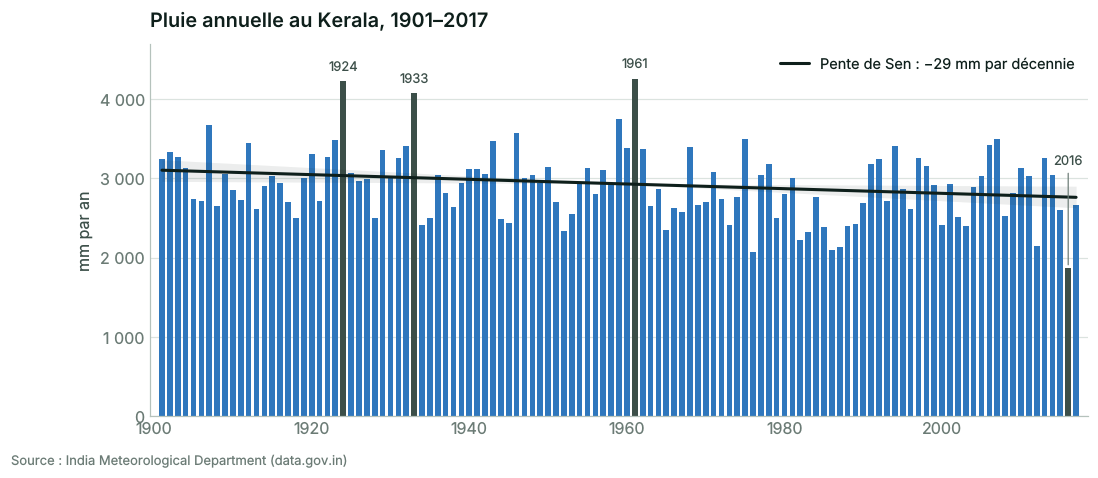

In [3]:
annual = rain["ANNUAL"]
sen = stats.sen_mann_kendall(annual)
extremes = stats.two_sigma_outliers(annual)

fig, ax = plt.subplots(figsize=(11, 4.4))
plotting.annual_bars(ax, annual, highlight={year: plotting.INK_2 for year in annual[extremes].index})
trend_label = f"Pente de Sen : {sen.per_decade:+.0f} mm par décennie".replace("-", "−")
plotting.trend_line(ax, sen, annual.index.to_numpy(), trend_label)
ax.set_ylim(0, 4700)
plotting.label_bars(ax, annual, list(annual[extremes].index))
ax.set_title("Pluie annuelle au Kerala, 1901–2017")
ax.set_ylabel("mm par an")
ax.legend(loc="upper right")
plotting.source_note(fig)
plotting.save(fig, "tendance_pluie_annuelle")
plt.show()

**Lecture.** Les barres sombres sont les années à plus de deux écarts-types de la moyenne
(1924, 1933, 1961 et 2016). La première version du projet les retirait comme « valeurs
aberrantes ». Ce ne sont pourtant pas des erreurs de saisie mais de vrais extrêmes
climatiques : 1924 est l'année de la « grande crue de 99 » (année 1099 du calendrier
malayalam) et 2016 l'année la plus sèche de la série. Nous les conservons et utilisons des
méthodes robustes, qui n'ont pas besoin de les écarter.

La **pente de Sen** est la médiane des pentes entre toutes les paires d'années : elle est peu
sensible aux extrêmes. Le **test de Mann-Kendall** vérifie, sans hypothèse de normalité, si la
série a une tendance monotone. Le tableau ci-dessous compare plusieurs méthodes, dont celles de
la première version (moindres carrés avec intervalle de confiance par bootstrap, suppression des
années à ±2σ), conservées comme vérification.

In [4]:
summary = stats.trend_summary(annual)
show(summary, 1)

first, last = annual.index.min(), annual.index.max()
change = sen.predict(last) - sen.predict(first)
print(f"Droite de Sen : {sen.predict(first):.0f} mm en {first} → {sen.predict(last):.0f} mm en {last}, "
      f"soit {change:+.0f} mm ({change / sen.predict(first):+.0%})")
print(f"Extrapolation naïve à 2050 : {sen.predict(2050):.0f} mm")

,pente / décennie,IC 95 % bas,IC 95 % haut,p-valeur,années
méthode,,,,,
Sen + Mann-Kendall,-29.5,-52.2,-5.3,"0,013",117
Sen + Mann-Kendall corrigé (Hamed-Rao),-29.5,-52.2,-5.3,"< 0,001",117
Moindres carrés,-32.6,-55.3,-10.0,"0,005",117
Moindres carrés sans les années à ±2σ,-23.6,-43.7,-3.4,"0,022",113
"Moindres carrés, IC par bootstrap",-32.6,-55.0,-12.1,,117


Droite de Sen : 3102 mm en 1901 → 2760 mm en 2017, soit -342 mm (-11%)
Extrapolation naïve à 2050 : 2663 mm


**Lecture.** Toutes les méthodes concluent à une **baisse significative** : environ
−30 mm par décennie (pente de Sen : −29 mm, IC 95 % [−52 ; −5], p = 0,013). Le retrait des années
extrêmes atténue la pente (−24 mm par décennie) sans changer la conclusion, et la correction de
l'autocorrélation (Hamed-Rao) ne la remet pas en cause. Sur la période, la pluie annuelle
« typique » passe d'environ 3 100 mm à 2 760 mm, soit −11 %.

L'extrapolation à 2050 (≈ 2 660 mm) est donnée à titre indicatif seulement : une tendance
passée n'est pas une projection climatique, qui demanderait des modèles physiques et des
scénarios d'émissions.

## 3. La mousson : saisonnalité, tendance et variabilité

<img src="../assets/img/mousson.gif" alt="Animation de la mousson" width="380">

La mousson est un régime de vents saisonniers. En été, le continent indien se réchauffe plus vite
que l'océan : les vents du sud-ouest, chargés d'humidité, remontent de la mer d'Arabie et
butent sur les Ghats occidentaux, qui forcent l'air à s'élever et à se condenser. C'est la
**mousson du sud-ouest** (juin–septembre). Une seconde saison des pluies, plus faible, accompagne
le retrait de la mousson (**mousson du nord-est**, octobre–décembre).

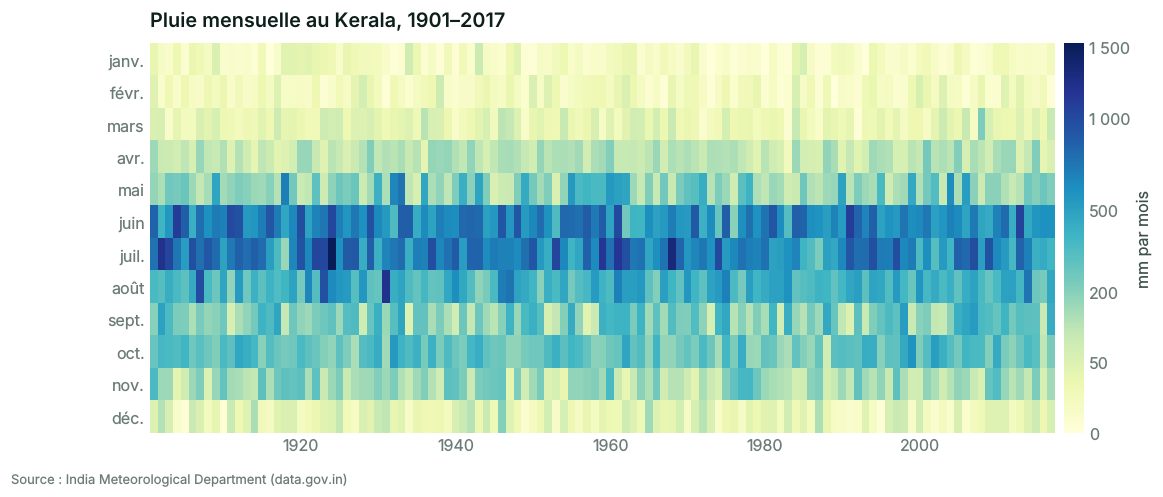

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.6))
image = plotting.month_year_heatmap(ax, rain)
plotting.sqrt_colorbar(fig, image, ax, (0, 50, 200, 500, 1000, 1500), "mm par mois")
ax.set_title("Pluie mensuelle au Kerala, 1901–2017")
plotting.source_note(fig)
plt.show()

**Lecture.** La couleur suit la racine carrée de la pluie pour que l'on distingue aussi les mois
secs. La pluie est concentrée de juin à septembre ; juillet 1924 (1 526 mm) reste le mois le plus
arrosé de toute la série. Octobre et novembre portent la trace de la mousson du nord-est.

Part de chaque saison dans la pluie totale 1901–2017 :
Hiver                    0.9%
Pré-mousson             12.9%
Mousson du sud-ouest    69.2%
Mousson du nord-est     17.0%


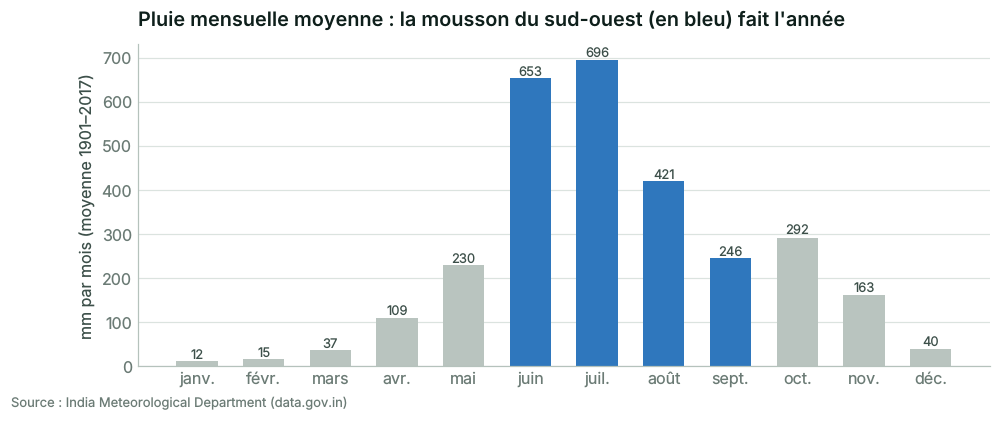

In [6]:
seasons = {"JF": "Hiver", "MAM": "Pré-mousson", "JJAS": "Mousson du sud-ouest", "OND": "Mousson du nord-est"}
shares = pd.Series({label: rain[key].sum() / rain["ANNUAL"].sum() for key, label in seasons.items()})
print("Part de chaque saison dans la pluie totale 1901–2017 :")
print(shares.map("{:.1%}".format).to_string())

climatology = rain.loc[:, list(data.MONTHS)].mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
plotting.emphasis_bars(ax, list(data.MONTHS_FR), climatology.to_numpy(), {"juin", "juil.", "août", "sept."})
ax.set_title("Pluie mensuelle moyenne : la mousson du sud-ouest (en bleu) fait l'année")
ax.set_ylabel("mm par mois (moyenne 1901–2017)")
plotting.source_note(fig)
plt.show()

**Lecture.** La mousson du sud-ouest apporte **69 %** de la pluie annuelle et la mousson du
nord-est 17 %. Juin et juillet sont les deux mois les plus arrosés (près de 700 mm chacun en
moyenne).

### La mousson faiblit-elle ?

In [7]:
labels = {"ANNUAL": "Année entière", "JJAS": "Mousson du sud-ouest", "OND": "Mousson du nord-est",
          "MAM": "Pré-mousson", "JF": "Hiver"}
show(stats.trends_by_column(rain, labels), 1)

,moyenne,pente / décennie,IC 95 % bas,IC 95 % haut,variation / siècle (% de la moyenne),p-valeur
série,,,,,,
Année entière,2914.2,-29.5,-52.2,-5.3,-10.1,"0,013"
Mousson du sud-ouest,2015.7,-24.9,-44.2,-5.2,-12.4,"0,013"
Mousson du nord-est,494.5,-6.6,-14.1,0.8,-13.4,"0,076"
Pré-mousson,376.5,-0.2,-6.4,6.1,-0.6,"0,949"
Hiver,27.5,-1.1,-2.1,-0.2,-39.1,"0,020"


**Lecture.** La baisse annuelle vient surtout de la **mousson du sud-ouest** : −25 mm par décennie
(p = 0,013), soit −12 % de son volume moyen par siècle. La pré-mousson ne montre aucune
tendance et la baisse de la mousson du nord-est n'est pas significative (p = 0,08). L'hiver
baisse en proportion (−39 % par siècle), mais il ne représente qu'environ 1 % de la pluie
annuelle.

### Les moussons sèches

Nous avions défini une mousson « sèche » comme une mousson inférieure à **70 % de la moyenne**
(environ 1 410 mm sur quatre mois, soit ≈ 350 mm par mois, la pluie d'un mois ordinaire hors
mousson). Nous la comparons avec la catégorie « déficitaire » de l'IMD (écart d'au moins −20 % à
la normale ; nous prenons ici la moyenne 1901–2017 comme normale).

Moussons sèches (< 70 % de la moyenne, 1411 mm) : [1918, 1976, 1987, 2002, 2016]
Moussons déficitaires (< 80 %, 1613 mm) : [1918, 1944, 1952, 1965, 1966, 1972, 1976, 1986, 1987, 2002, 2003, 2012, 2015, 2016]
Moussons déficitaires par période : {'1901–1930': 1, '1931–1960': 2, '1961–1990': 6, '1991–2017': 5}


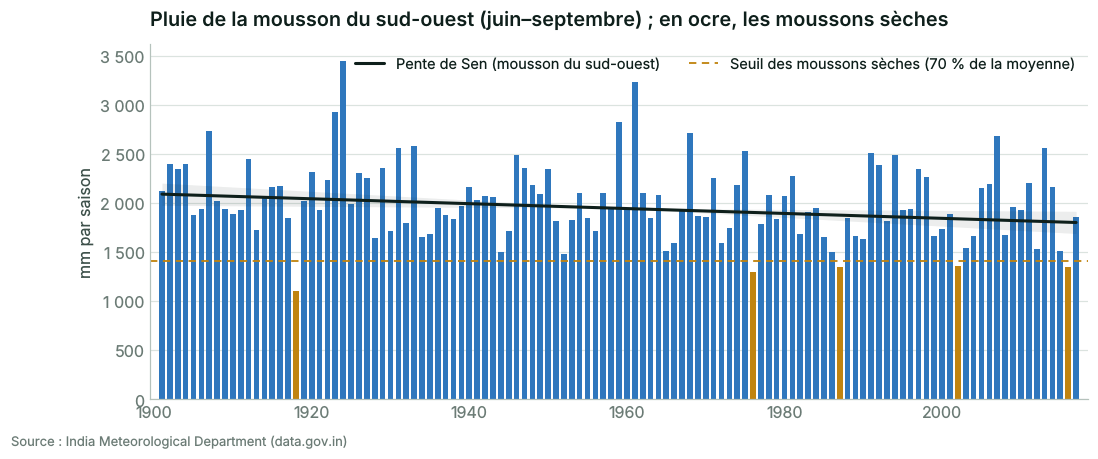

In [8]:
jjas = rain["JJAS"]
dry = stats.deficient_years(jjas, 0.7)
deficient = stats.deficient_years(jjas, 0.8)
print(f"Moussons sèches (< 70 % de la moyenne, {0.7 * jjas.mean():.0f} mm) : {list(dry.index)}")
print(f"Moussons déficitaires (< 80 %, {0.8 * jjas.mean():.0f} mm) : {list(deficient.index)}")
periods = pd.cut(deficient.index, [1900, 1930, 1960, 1990, 2017], labels=["1901–1930", "1931–1960", "1961–1990", "1991–2017"])
print("Moussons déficitaires par période :", pd.Series(periods).value_counts(sort=False).to_dict())

fig, ax = plt.subplots(figsize=(11, 4.2))
plotting.annual_bars(ax, jjas, highlight={year: plotting.DRY for year in dry.index})
plotting.trend_line(ax, stats.sen_mann_kendall(jjas), jjas.index.to_numpy(), "Pente de Sen (mousson du sud-ouest)")
ax.axhline(0.7 * jjas.mean(), color=plotting.DRY, lw=1.2, ls=(0, (4, 3)), label="Seuil des moussons sèches (70 % de la moyenne)")
ax.set_title("Pluie de la mousson du sud-ouest (juin–septembre) ; en ocre, les moussons sèches")
ax.set_ylabel("mm par saison")
ax.legend(loc="upper right", ncols=2)
plotting.source_note(fig)
plt.show()

**Lecture.** Cinq moussons passent sous le seuil de 70 % : 1918, 1976, 1987, 2002 et 2016,
dont quatre après 1975. Avec le seuil « déficitaire » de l'IMD, on compte 14 moussons, dont 11
depuis 1961 (3 seulement entre 1901 et 1960). Attention à l'interprétation : avec un **seuil
fixe**, une moyenne qui baisse suffit à multiplier les années déficitaires, même si la
variabilité ne change pas. C'est ce que nous vérifions maintenant.

### La mousson devient-elle plus instable ?

La première version du projet concluait, en comparant les variances de 1901–1920 et de
2000–2017, à une variance « beaucoup plus élevée » au début du XXIᵉ siècle. Un écart de variance
entre deux petits échantillons peut être dû au hasard : il faut le **tester**. Nous utilisons le
test de Brown-Forsythe (test de Levene centré sur la médiane), robuste aux distributions
asymétriques comme la pluie, et le coefficient de variation (écart-type / moyenne) sur des
fenêtres glissantes de 30 ans.

,écart-type 1901–1920,écart-type 2000–2017,CV 1901–1920,CV 2000–2017,p-valeur
série,,,,,
Année entière,315.0,433.0,0.105,0.155,"0,189"
Mousson du sud-ouest,340.0,385.0,0.164,0.204,"0,397"


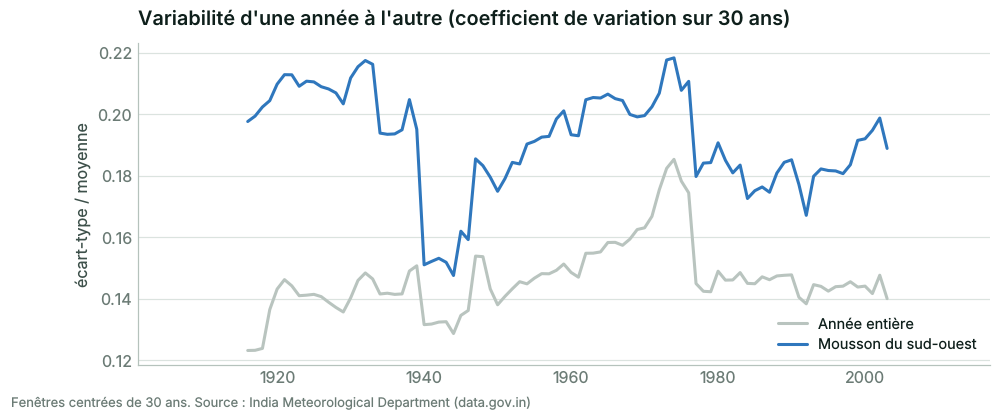

In [9]:
rows = []
for key, label in {"ANNUAL": "Année entière", "JJAS": "Mousson du sud-ouest"}.items():
    result = stats.compare_periods(rain[key], (1901, 1920), (2000, 2017))
    rows.append({"série": label, "écart-type 1901–1920": result.std_a, "écart-type 2000–2017": result.std_b,
                 "CV 1901–1920": result.cv_a, "CV 2000–2017": result.cv_b, "p-valeur": result.levene_p})
show(pd.DataFrame(rows).set_index("série"), {"écart-type 1901–1920": 0, "écart-type 2000–2017": 0,
                                             "CV 1901–1920": 3, "CV 2000–2017": 3})

cv_jjas = stats.rolling_cv(jjas)
cv_annual = stats.rolling_cv(annual)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(cv_annual.index, cv_annual, color=plotting.CONTEXT, label="Année entière")
ax.plot(cv_jjas.index, cv_jjas, color=plotting.RAIN, label="Mousson du sud-ouest")
ax.set_title("Variabilité d'une année à l'autre (coefficient de variation sur 30 ans)")
ax.set_ylabel("écart-type / moyenne")
ax.set_xlim(1901, 2017)
ax.legend(loc="lower right")
plotting.source_note(fig, "Fenêtres centrées de 30 ans. " + plotting.SOURCE_IMD)
plt.show()

**Lecture.** L'écart-type augmente bien entre 1901–1920 et 2000–2017 (de 315 à 433 mm pour
l'année entière), mais **la différence n'est pas significative** (p = 0,19 pour l'année et
p = 0,40 pour la mousson) : avec une vingtaine d'années par période, un tel écart peut apparaître
par hasard. Sur des fenêtres de 30 ans, le coefficient de variation de la mousson oscille entre
0,15 et 0,22, avec un maximum vers 1960–1990, sans hausse continue. **Les données ne démontrent
donc pas une mousson plus instable** : c'est surtout son volume moyen qui baisse.

### La saison se décale-t-elle vers l'automne ?

Sur les cartes de chaleur, septembre et octobre semblaient plus sollicités au début du XXIᵉ
siècle. Nous comparons la part de chaque mois dans le total annuel entre les 30 premières
(1901–1930) et les 30 dernières années (1988–2017), avec un test de Mann-Whitney.

,part 1901–1930,part 1988–2017,p-valeur
janv.,0.6,0.3,"0,027"
févr.,0.6,0.6,"0,631"
mars,1.2,1.4,"0,784"
avr.,3.2,4.1,"0,137"
mai,7.2,7.8,"0,796"
juin,23.3,22.4,"0,589"
juil.,24.7,22.3,"0,112"
août,13.9,14.4,"0,412"
sept.,8.0,9.6,"0,109"
oct.,10.0,11.0,"0,355"


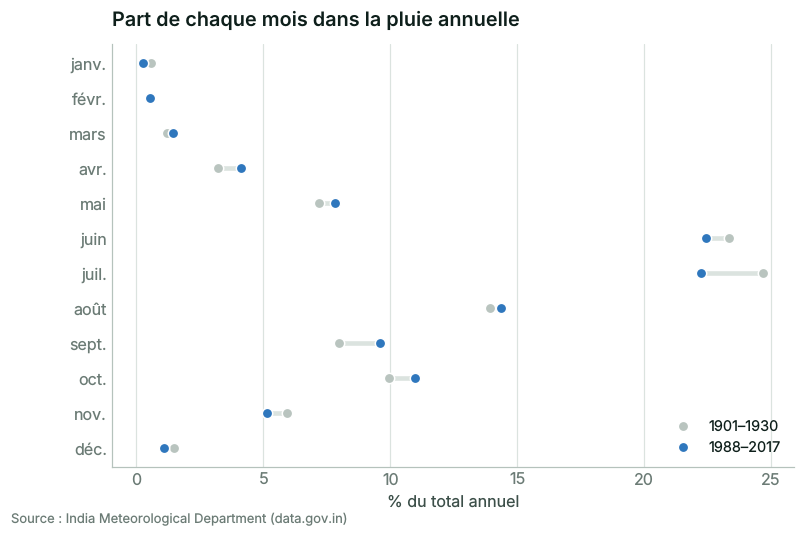

In [10]:
shares = stats.month_shares(rain, data.MONTHS)
tests = [stats.compare_periods(shares[m], (1901, 1930), (1988, 2017)) for m in data.MONTHS]
share_table = pd.DataFrame(
    {"part 1901–1930": [t.mean_a for t in tests], "part 1988–2017": [t.mean_b for t in tests],
     "p-valeur": [t.mann_whitney_p for t in tests]},
    index=list(data.MONTHS_FR),
)
show(share_table * [100, 100, 1], 1)

fig, ax = plt.subplots(figsize=(8, 5))
plotting.dumbbell(ax, list(data.MONTHS_FR), 100 * share_table["part 1901–1930"].to_numpy(),
                  100 * share_table["part 1988–2017"].to_numpy(), ("1901–1930", "1988–2017"))
ax.set_title("Part de chaque mois dans la pluie annuelle")
ax.set_xlabel("% du total annuel")
ax.legend(loc="lower right")
plotting.source_note(fig)
plt.show()

**Lecture.** Juillet perd un peu de poids (24,7 % → 22,3 %), septembre (8,0 % → 9,6 %) et
octobre (10,0 % → 11,0 %) en gagnent, mais **aucune différence n'est significative**
(p ≥ 0,11). L'« extension » de la mousson vers l'automne reste une piste à confirmer avec
des données plus fines (journalières) plutôt qu'un résultat établi.

### Résultats de la partie

La mousson du sud-ouest fournit 69 % de la pluie du Kerala, et c'est elle qui porte la baisse
significative des précipitations depuis 1901 (−25 mm par décennie). Les moussons déficitaires
sont plus fréquentes depuis les années 1960, ce qui s'explique par la baisse de la moyenne ; une
hausse de la variabilité ou un décalage de la saison ne sont pas démontrés par ces données.

## 4. Un événement extrême : les inondations d'août 2018

<img src="../assets/img/inondations_2018.jpg" alt="Inondations au Kerala en 2018" width="420">

En août 2018, le Kerala subit les pires inondations depuis 1924. Plus d'un million de personnes
sont déplacées. Nous disposons d'un tableau par district : décès, camps de secours, pluie
observée et pluie normale, glissements de terrain et maisons entièrement détruites.

In [11]:
floods = data.load_floods_2018()
districts = district_table(data.load_districts_geojson())
totals = floods[["fatalities", "landslides", "houses_destroyed", "relief_camps"]].sum()
print(f"Décès : {totals['fatalities']} · glissements de terrain : {totals['landslides']} · "
      f"maisons détruites : {totals['houses_destroyed']:,} · camps de secours : {totals['relief_camps']:,}".replace(",", " "))
columns = ["rain_actual_mm", "rain_normal_mm", "departure_pct", "fatalities", "landslides", "houses_destroyed", "relief_camps"]
floods[columns].sort_values("departure_pct", ascending=False).round(0)

Décès : 339 · glissements de terrain : 331 · maisons détruites : 10 319 · camps de secours : 12 253


,rain_actual_mm,rain_normal_mm,departure_pct,fatalities,landslides,houses_destroyed,relief_camps
district,,,,,,,
Idukki,1479.0,527.0,180.0,54,143,1166,363
Thiruvananthapuram,374.0,142.0,163.0,11,0,111,94
Palakkad,849.0,334.0,154.0,20,20,1118,165
Kollam,644.0,259.0,149.0,5,2,95,168
Malappuram,914.0,395.0,131.0,30,30,500,213
Pathanamthitta,765.0,353.0,117.0,3,8,741,4352
Wayanad,1054.0,593.0,78.0,6,47,702,451
Alappuzha,608.0,343.0,77.0,43,0,2075,2126
Thrissur,735.0,440.0,67.0,72,26,2889,1513


Le tableau ne précise pas la période couverte. Nous la vérifions en calculant la moyenne de la
pluie des districts **pondérée par leur surface**, et en la comparant au chiffre officiel de
l'IMD pour l'ensemble du Kerala en août 2018.

In [12]:
imd = data.load_imd_2018()
weighted_actual = area_weighted_mean(floods["rain_actual_mm"], districts["area_km2"])
weighted_normal = area_weighted_mean(floods["rain_normal_mm"], districts["area_km2"])
print(f"Districts (pondérés par la surface) : {weighted_actual:.0f} mm observés pour {weighted_normal:.0f} mm normaux")
print(f"IMD, Kerala, août 2018 : {imd.loc['AUG', 'actual_mm']} mm observés pour {imd.loc['AUG', 'normal_mm']} mm normaux "
      f"({imd.loc['AUG', 'departure_pct']:+d} %)")

Districts (pondérés par la surface) : 833 mm observés pour 421 mm normaux
IMD, Kerala, août 2018 : 821.9 mm observés pour 419.5 mm normaux (+96 %)


Les deux estimations concordent (833 contre 822 mm, 421 contre 420 mm) : le tableau décrit bien
**le mois d'août 2018**. Nous pouvons maintenant cartographier la pluie et ses conséquences.

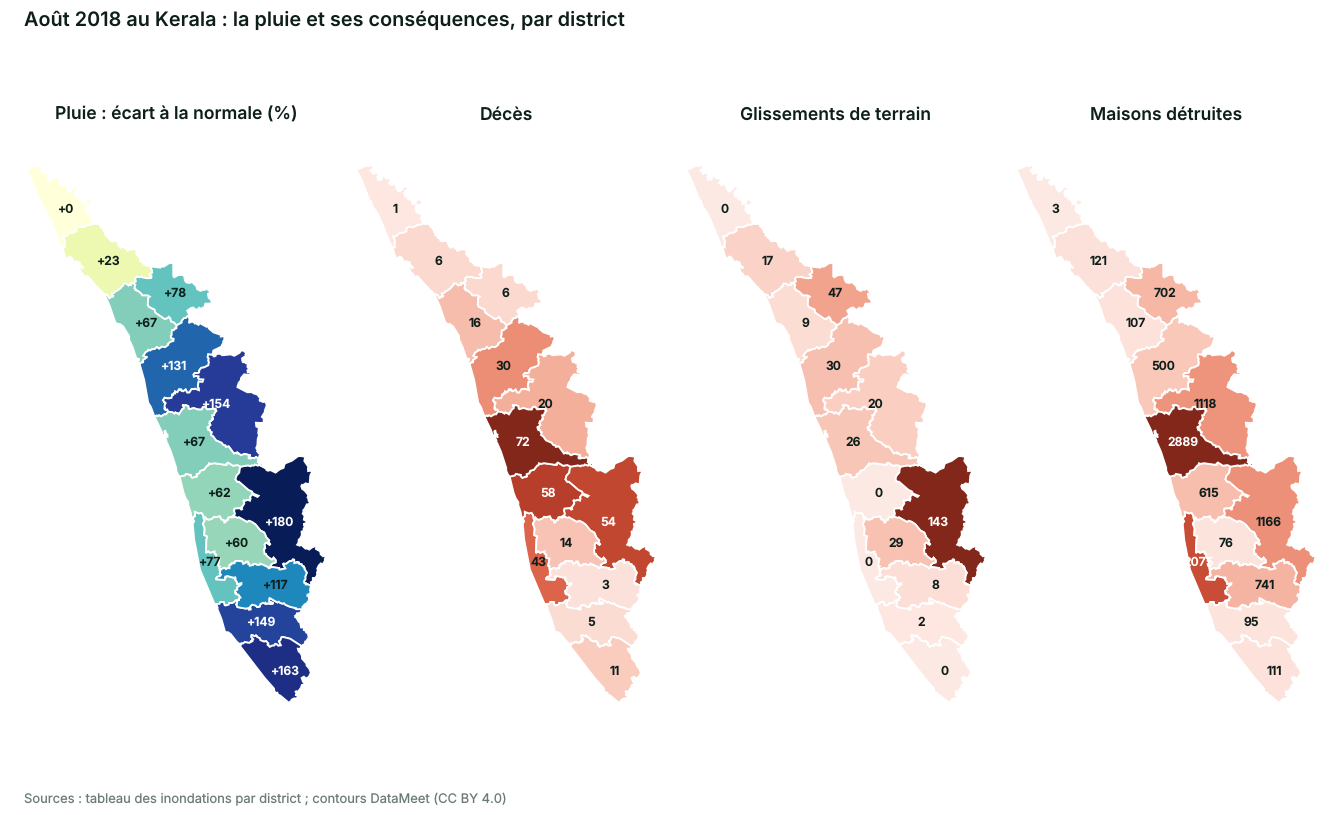

In [13]:
geojson = data.load_districts_geojson()
panels = [
    ("departure_pct", "Pluie : écart à la normale (%)", plotting.RAIN_CMAP, "{:+.0f}"),
    ("fatalities", "Décès", plotting.TOLL_CMAP, "{:.0f}"),
    ("landslides", "Glissements de terrain", plotting.TOLL_CMAP, "{:.0f}"),
    ("houses_destroyed", "Maisons détruites", plotting.TOLL_CMAP, "{:.0f}"),
]
fig, axes = plt.subplots(1, 4, figsize=(12, 7.4))
for ax, (column, title, colormap, fmt) in zip(axes, panels):
    plotting.choropleth(ax, geojson, floods[column], colormap, vmin=0, fmt=fmt)
    ax.set_title(title, fontsize=11.5, loc="center")
fig.subplots_adjust(left=0.0, right=1.0, top=0.88, bottom=0.04, wspace=0.0)
fig.suptitle("Août 2018 au Kerala : la pluie et ses conséquences, par district", x=0.01, ha="left",
             fontsize=13, fontweight="semibold")
plotting.source_note(fig, "Sources : tableau des inondations par district ; contours DataMeet (CC BY 4.0)")
plotting.save(fig, "aout_2018_par_district")
plt.show()

**Lecture.** Tous les districts sauf Kasaragod reçoivent plus que la normale, jusqu'à +180 %
dans l'Idukki, district montagneux des Ghats. Mais la carte des décès ne ressemble pas à celle de
la pluie : Thrissur (72 décès), Ernakulam (58) et Alappuzha (43), en plaine, comptent parmi les
plus touchés. Vérifions-le avec une corrélation de rang (Spearman), adaptée à 14 points et à des
valeurs très dispersées.

,rho de Spearman,p-valeur
impact,,
Glissements de terrain,0.76,"0,002"
Décès,0.20,"0,493"
Maisons détruites,0.40,"0,159"


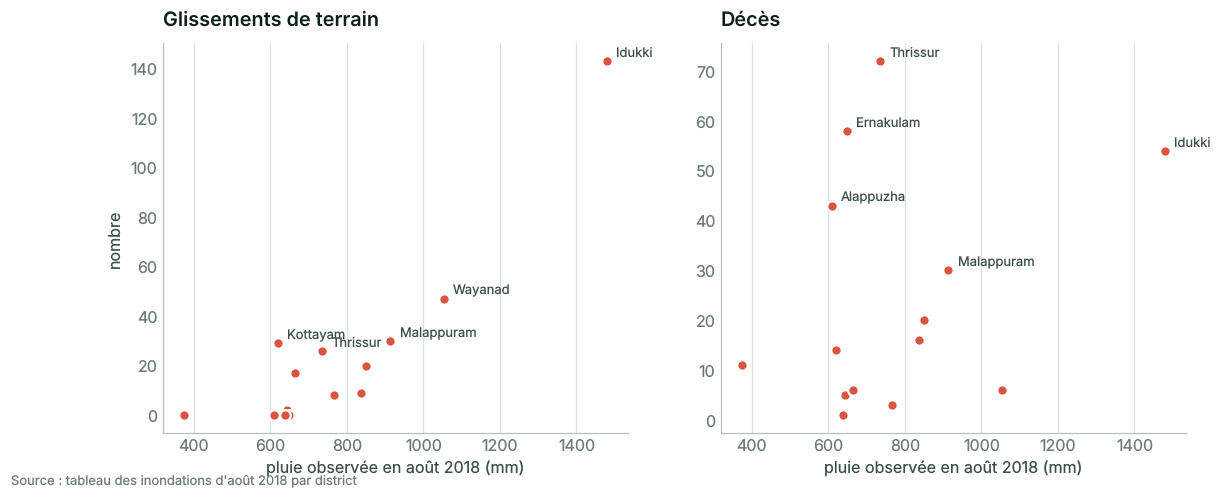

In [14]:
impacts = {"landslides": "Glissements de terrain", "fatalities": "Décès", "houses_destroyed": "Maisons détruites"}
correlations = pd.DataFrame(
    [dict(zip(["impact", "rho de Spearman", "p-valeur"], [label, *stats.spearman(floods["rain_actual_mm"], floods[key])]))
     for key, label in impacts.items()]
).set_index("impact")
show(correlations, 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, key in zip(axes, ["landslides", "fatalities"]):
    plotting.labelled_scatter(ax, floods["rain_actual_mm"], floods[key])
    ax.set_title(impacts[key])
    ax.set_xlabel("pluie observée en août 2018 (mm)")
axes[0].set_ylabel("nombre")
plotting.source_note(fig, "Source : tableau des inondations d'août 2018 par district")
plt.show()

**Lecture.** La pluie explique bien les **glissements de terrain** (ρ = 0,76, p = 0,002) : ils se
concentrent sur les pentes des Ghats (143 dans l'Idukki). Elle n'explique pas le **nombre de
décès** (ρ = 0,20, p = 0,49) : les plaines inondables, densément peuplées, paient le plus lourd
tribut. L'exposition (population, urbanisation des zones inondables) compte autant que l'aléa.

### Août 2018 était-il un record ?

La première version comparait le district le plus arrosé en 2018 (Idukki, 1 479 mm) au maximum
historique **de l'État** : la comparaison était biaisée, un district n'étant pas l'État entier.
Nous comparons ici des grandeurs comparables : la pluie d'août de l'État, de 1901 à 2017, et le
chiffre officiel de l'IMD pour août 2018.

Août 2018 : 821.9 mm, rang 4 depuis 1901
Mois d'août les plus pluvieux : {1931: 1199.2, 1907: 981.5, 1923: 943.0}
Mousson 2018 (juin–sept.) : 2517.2 mm (+23 %), rang 12 depuis 1901


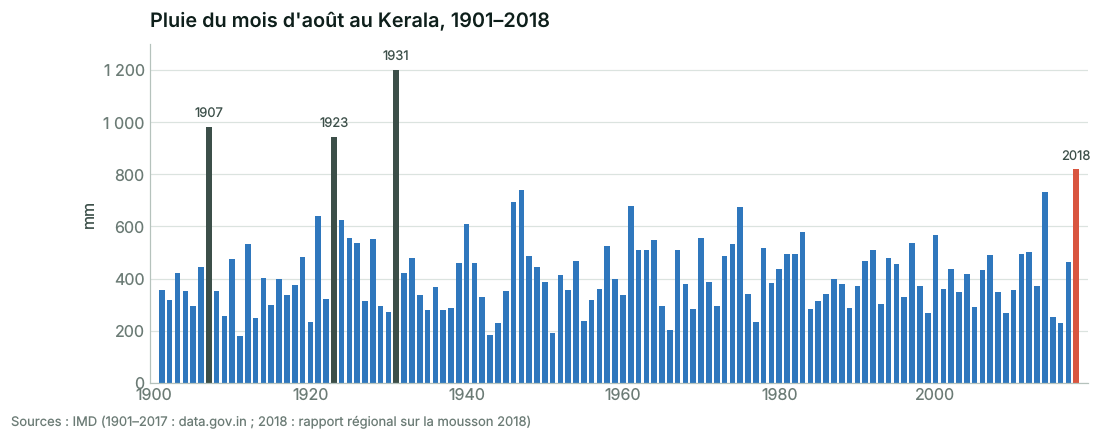

In [15]:
august = rain["AUG"]
august_2018 = imd.loc["AUG", "actual_mm"]
print(f"Août 2018 : {august_2018} mm, rang {stats.rank_in_history(august_2018, august)} depuis 1901")
print("Mois d'août les plus pluvieux :", august.nlargest(3).to_dict())
print(f"Mousson 2018 (juin–sept.) : {imd.loc['JJAS', 'actual_mm']} mm ({imd.loc['JJAS', 'departure_pct']:+d} %), "
      f"rang {stats.rank_in_history(imd.loc['JJAS', 'actual_mm'], rain['JJAS'])} depuis 1901")

history = pd.concat([august, pd.Series({2018: august_2018})])
fig, ax = plt.subplots(figsize=(11, 4))
plotting.annual_bars(ax, history, highlight={2018: plotting.CORAL, 1931: plotting.INK_2, 1907: plotting.INK_2, 1923: plotting.INK_2})
ax.set_ylim(0, 1300)
plotting.label_bars(ax, history, [1907, 1923, 1931, 2018])
ax.set_title("Pluie du mois d'août au Kerala, 1901–2018")
ax.set_ylabel("mm")
plotting.source_note(fig, "Sources : IMD (1901–2017 : data.gov.in ; 2018 : rapport régional sur la mousson 2018)")
plotting.save(fig, "aout_2018_dans_l_histoire")
plt.show()

**Lecture.** Avec 821,9 mm (+96 %), août 2018 est le **4ᵉ mois d'août le plus pluvieux depuis
1901**, derrière 1931 (1 199 mm), 1907 et 1923, et la mousson 2018 (+23 %) se classe 12ᵉ. Ce
n'est pas le volume du mois qui est inédit, mais sa **concentration** : selon l'IMD, les 14
districts ont connu des pluies très fortes ou extrêmes entre le 14 et le 17 août, avec jusqu'à
40 cm en une journée à Nilambur (9 août) et 35 cm à Peermade (16 août). Ces pluies tombaient
après un juin (+15 %) et un juillet (+18 %) déjà excédentaires, sur des sols vraisemblablement
saturés. Le précédent historique reste juillet 1924 (1 526 mm), la « grande crue de 99 ».

### Résultats de la partie

Les inondations de 2018 ont fait 339 morts, détruit 10 319 maisons et provoqué 331 glissements
de terrain. La pluie, presque deux fois supérieure à la normale, a frappé tout l'État, mais
les dégâts ne lui sont pas proportionnels : les glissements suivent la pluie et le relief, les
décès suivent l'exposition des plaines peuplées. Ces inondations se sont répétées, plus
modérément, en 2019 et 2020.

## 5. L'évolution des températures en Inde

Nous n'avons pas trouvé de série de températures propre au Kerala sur plus d'un siècle. Nous
utilisons donc une série **pour l'ensemble de l'Inde** (IMD), qui inclut le Kerala mais ne permet
pas de corréler directement température et pluie au Kerala.

<img src="../assets/img/chaleur_2021.jpg" alt="Vague de chaleur en Asie du Sud" width="380">

In [16]:
temps = data.load_temperatures()
print(f"{len(temps)} années ({temps.index.min()}–{temps.index.max()}) ; moyenne annuelle "
      f"de {temps['ANNUAL'].min():.1f} à {temps['ANNUAL'].max():.1f} °C")
temps[["ANNUAL", "JF", "MAM", "JJAS", "OND"]].describe().round(2)

117 années (1901–2017) ; moyenne annuelle de 28.1 à 31.6 °C


,ANNUAL,JF,MAM,JJAS,OND
count,117.00,117.00,117.00,117.00,117.00
mean,29.18,24.63,31.52,31.20,27.21
std,0.56,0.91,0.74,0.42,0.67
min,28.11,22.25,29.92,30.24,25.74
25%,28.76,24.11,31.04,30.92,26.70
50%,29.09,24.53,31.47,31.19,27.21
75%,29.47,25.15,31.89,31.40,27.61
max,31.63,28.33,34.57,32.41,30.03


**Quelle température ?** Le fichier ne le précise pas. Ses valeurs annuelles (29 à 31,6 °C) sont
bien supérieures à la température moyenne de l'Inde (environ 25 °C) : il s'agit très
probablement de la moyenne des **températures maximales** journalières. Nous interprétons donc
des tendances, pas des niveaux absolus.

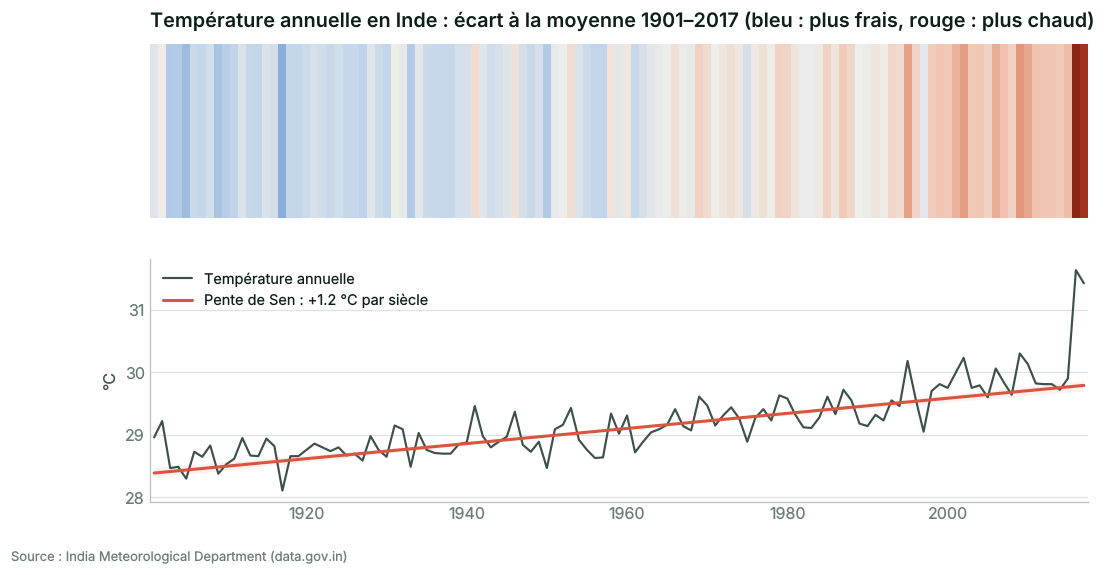

,moyenne,pente / décennie,IC 95 % bas,IC 95 % haut,variation / siècle (% de la moyenne),p-valeur
série,,,,,,
Année,29.18,0.12,0.11,0.13,4.13,"< 0,001"
Janv.–févr.,24.63,0.16,0.13,0.20,6.66,"< 0,001"
Mars–mai,31.52,0.13,0.10,0.16,4.05,"< 0,001"
Juin–sept.,31.20,0.08,0.06,0.10,2.50,"< 0,001"
Oct.–déc.,27.21,0.14,0.12,0.16,5.27,"< 0,001"


In [17]:
annual_temp = temps["ANNUAL"]
temp_trend = stats.sen_mann_kendall(annual_temp)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
plotting.warming_stripes(top, annual_temp)
top.set_title("Température annuelle en Inde : écart à la moyenne 1901–2017 (bleu : plus frais, rouge : plus chaud)")
bottom.plot(annual_temp.index, annual_temp, color=plotting.INK_2, lw=1.4, label="Température annuelle")
plotting.trend_line(bottom, temp_trend, annual_temp.index.to_numpy(),
                    f"Pente de Sen : {temp_trend.per_century:+.1f} °C par siècle", color=plotting.CORAL)
bottom.set_ylabel("°C")
bottom.legend(loc="upper left")
plotting.source_note(fig)
plt.show()

show(stats.trends_by_column(temps, {"ANNUAL": "Année", "JF": "Janv.–févr.", "MAM": "Mars–mai",
                                    "JJAS": "Juin–sept.", "OND": "Oct.–déc."}), 2)

**Lecture.** La hausse est nette et régulière : **+1,2 °C par siècle** pour l'année (p < 0,001),
et toutes les saisons se réchauffent, de +0,8 °C par siècle pendant la mousson à +1,6 °C en
janvier–février. 2016 et 2017 sont les deux années les plus chaudes de la série.

La première version comparait les deux moitiés de la série avec une ANOVA présentée comme
« non paramétrique ». Or l'ANOVA est un test **paramétrique** (moyennes, hypothèse de normalité),
et avec deux groupes elle équivaut au test t de Student. Nous utilisons le test t de Welch
(variances inégales) et son équivalent non paramétrique, le test de Mann-Whitney.

In [18]:
rows = []
for key, label in {"ANNUAL": "Année", "JF": "Janv.–févr.", "MAM": "Mars–mai", "JJAS": "Juin–sept.", "OND": "Oct.–déc."}.items():
    result = stats.compare_periods(temps[key], (1901, 1959), (1960, 2017))
    rows.append({"saison": label, "moyenne 1901–1959": result.mean_a, "moyenne 1960–2017": result.mean_b,
                 "écart (°C)": result.difference, "p-valeur": result.welch_p, "p Mann-Whitney": result.mann_whitney_p})
halves = pd.DataFrame(rows).set_index("saison")
halves["p Mann-Whitney"] = halves["p Mann-Whitney"].map(stats.format_p)
show(halves, 2)

,moyenne 1901–1959,moyenne 1960–2017,écart (°C),p-valeur,p Mann-Whitney
saison,,,,,
Année,28.81,29.56,0.75,"< 0,001","< 0,001"
Janv.–févr.,24.10,25.16,1.06,"< 0,001","< 0,001"
Mars–mai,31.14,31.90,0.76,"< 0,001","< 0,001"
Juin–sept.,30.94,31.46,0.52,"< 0,001","< 0,001"
Oct.–déc.,26.79,27.63,0.84,"< 0,001","< 0,001"


**Lecture.** Les deux tests concluent à une différence très significative pour toutes les
saisons (p < 0,001) : la seconde moitié du siècle est plus chaude de 0,5 à 1,1 °C.

Pour le Kerala lui-même, la littérature apporte un éclairage complémentaire : une étude du
district de Kottayam ([Sreeraj et Vijayakumar, 2021](../references/sreeraj_vijayakumar_2021_kottayam_temperatures.pdf))
trouve, pour la pré-mousson 1991–2014, une baisse des températures maximales et une hausse des
minimales.

### Résultats de la partie

L'Inde se réchauffe nettement depuis 1901, en toutes saisons. Ces données ne suffisent pas à
relier ce réchauffement à la baisse des pluies au Kerala : c'est la littérature scientifique
(GIEC) qui établit, à grande échelle, le lien entre réchauffement, mousson et événements
extrêmes.

## 6. Et l'agriculture ?

<img src="../assets/img/agriculture_kerala.jpg" alt="Rizières au Kerala" width="380">

L'agriculture du Kerala (riz, caoutchouc, thé, poivre, noix de coco) dépend directement de la
mousson. Nous disposons d'un tableau d'occupation du sol en 1914, 1967 et 2007 pour une zone de
**483,4 km²**. Sa source n'était pas indiquée ; la superficie et les dates correspondent à
l'étude du bassin de la rivière Neyyar, au sud du Kerala (Sheeja et al., 2011), réalisée à
partir de cartes topographiques (1914, 1967) et d'images satellite (2006–2007).

In [19]:
land_use = data.load_land_use()
wide = data.land_use_wide(land_use)
print(f"Surface totale par année (km²) : {land_use.groupby('year')['area_km2'].sum().round(1).to_dict()}")
wide.round(1)

Surface totale par année (km²) : {1914: 483.4, 1967: 483.4, 2007: 483.4}


year,1914,1967,2007
label_fr,,,
Zones bâties,1.6,3.9,10.1
Rizières,41.3,12.8,11.5
Bananeraies,0.0,0.0,0.6
Cultures maraîchères,0.0,0.0,0.8
Hévéa (caoutchouc),0.0,9.0,57.7
Cocoteraies,NaN,6.8,3.5
Cultures mixtes (jardins arborés),270.5,306.5,256.7
Terrains rocheux,10.5,9.8,7.7
Sablières et friches industrielles,0.2,0.2,0.2


Forêt, toutes classes confondues (km²) : {1914: 115.6, 1967: 116.9, 2007: 116.8}


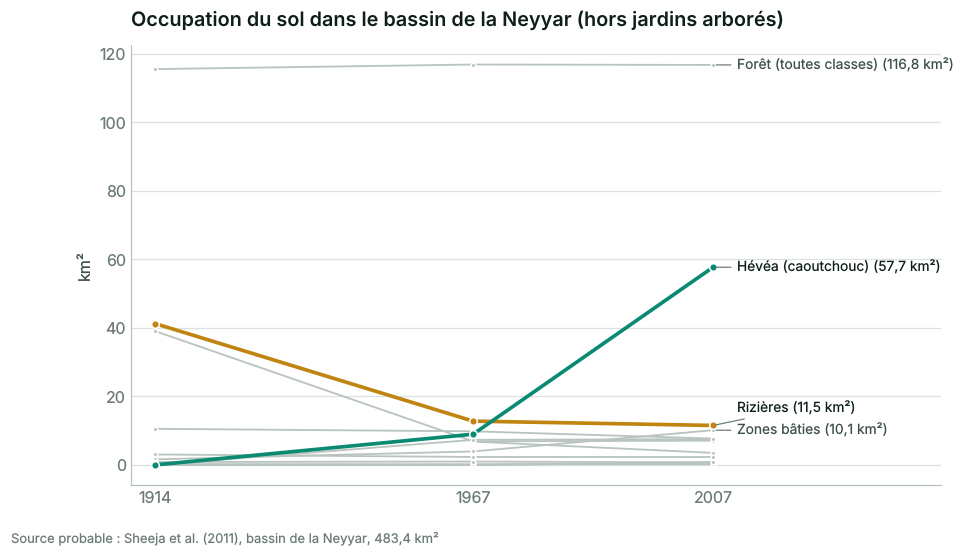

In [20]:
forest = land_use.query("group == 'Forest'").groupby("year")["area_km2"].sum()
print("Forêt, toutes classes confondues (km²) :", forest.round(1).to_dict())

forest_classes = ["Forêt sempervirente", "Forêt dense mixte", "Forêt claire", "Plantations d'eucalyptus"]
overview = wide.drop(index=["Cultures mixtes (jardins arborés)", *forest_classes])
overview.loc["Forêt (toutes classes)"] = forest
fig, ax = plt.subplots(figsize=(9.5, 5.2))
plotting.slope_chart(ax, overview, {"Rizières": plotting.PADDY, "Hévéa (caoutchouc)": plotting.RUBBER},
                     annotate=("Forêt (toutes classes)", "Zones bâties"))
ax.set_title("Occupation du sol dans le bassin de la Neyyar (hors jardins arborés)")
ax.set_ylabel("km²")
plotting.source_note(fig, "Source probable : Sheeja et al. (2011), bassin de la Neyyar, 483,4 km²")
plt.show()

**Lecture.** Les **rizières** passent de 41,3 à 11,5 km² (−72 %) tandis que l'**hévéa**
(caoutchouc), absent en 1914, couvre 57,7 km² en 2007 ; les zones bâties sont multipliées par six
(1,6 → 10,1 km²). La forêt sempervirente semble reculer de moitié, mais la surface forestière
totale reste stable (≈ 116 km²) : la carte de 2007 distingue de nouvelles classes (forêt dense
mixte, forêt claire). Ce tableau décrit un seul bassin versant, pas l'ensemble de l'État.

La conversion des rizières va dans le même sens à l'échelle du Kerala : selon [CABI (2018)](https://blog.cabi.org/2018/09/26/kerala-flooding-agricultural-impacts-and-environmental-degradation/),
une grande partie des rizières a été convertie en plantations ou remblayée pour construire. Or
les rizières inondées jouent un rôle d'éponge pendant les fortes pluies. En 2018, des milliers
d'hectares de cultures ont été endommagés.

## 7. Le climat, seul responsable ?

D'autres facteurs aggravent les conséquences d'une mousson extrême. G. M. Pillai, directeur du
World Institute of Sustainable Energy (Pune), attribue une part de la gravité des inondations au
développement non durable : conversion des rizières en plantations de caoutchouc, construction
de l'aéroport de Kochi sur des terres agricoles qui servaient de zone d'expansion des eaux,
déforestation et carrières illégales sur les pentes des Ghats.

Nos résultats vont dans ce sens : le bilan humain de 2018 dépend davantage de l'exposition des
territoires que de la quantité de pluie, et l'occupation du sol a profondément changé en un
siècle. L'homme, responsable du réchauffement climatique, aggrave aussi la vulnérabilité par
son usage des sols.

## 8. Conclusion et limites

**Ce que montrent les données**

- La mousson du sud-ouest apporte **69 %** de la pluie annuelle du Kerala.
- Les précipitations annuelles **baissent significativement** depuis 1901 : environ −30 mm par
  décennie (pente de Sen, p = 0,013), soit −11 % entre 1901 et 2017. La baisse vient surtout de
  la mousson du sud-ouest (−25 mm par décennie).
- Les moussons déficitaires sont plus fréquentes depuis 1960 (11 sur 14), ce qui découle de la
  baisse de la moyenne.
- Les températures de l'Inde augmentent d'environ **+1,2 °C par siècle**, en toutes saisons.
- En **août 2018**, le Kerala reçoit 821,9 mm (+96 %), 4ᵉ mois d'août le plus pluvieux depuis 1901,
  en pluies très concentrées (14–17 août). Bilan : 339 morts, 10 319 maisons détruites.
- La pluie explique les glissements de terrain (ρ = 0,76) mais pas le nombre de décès
  (ρ = 0,20) : l'exposition des plaines peuplées est déterminante.

**Ce que les données ne montrent pas**

- Une hausse significative de la variabilité de la mousson (Brown-Forsythe, p = 0,19 à 0,40).
- Un décalage significatif de la saison vers l'automne (Mann-Whitney, p ≥ 0,11).

**Limites**

- Les températures concernent toute l'Inde (vraisemblablement les maximales) et non le Kerala.
- Le tableau des inondations ne précise ni sa source ni sa période (nous avons vérifié qu'il
  couvre août 2018) ; les « camps » sont donnés tels quels.
- Le tableau d'occupation du sol décrit un bassin de 483 km², pas l'ensemble de l'État.
- Une tendance passée n'est pas une projection : pour 2050, il faudrait des modèles climatiques.

Ces observations rejoignent le GIEC, pour qui les événements extrêmes comme celui de 2018
devraient devenir plus fréquents avec le réchauffement ; le Kerala a d'ailleurs de nouveau été
inondé en 2019 et en 2020.

### Organisation du travail

Nous avons découpé le projet ensemble et réalisé les premières analyses à trois. Marwan s'est
davantage consacré à l'évolution de la mousson, qu'Ilan a complétée avant de poursuivre sur les
inondations de 2018. Youssef s'est concentré sur le climat en Inde et sur l'apport
bibliographique. La partie sur l'agriculture a été réalisée en groupe. Nous avons rencontré des
difficultés pour trouver des données sur le Kerala, et certaines sources indiquaient des
tendances contraires aux nôtres ; nous avons choisi de nous en tenir à ce que nos données
permettent de tester.

### Références

- IMD, *Sub-divisional monthly rainfall 1901–2017* et séries de températures de l'Inde, via
  [data.gov.in](https://data.gov.in).
- IMD, Regional Meteorological Centre Chennai, *Regional report on southwest monsoon – 2018 over
  the southern peninsular India* (2019),
  [mausam.imd.gov.in](https://mausam.imd.gov.in/chennai/mcdata/sw_monsoon_2018.pdf).
- Sheeja R. V., Joseph S., Jaya D. S., Baiju R. S. (2011). *Land use and land cover changes over
  a century (1914–2007) in the Neyyar River Basin, Kerala.* International Journal of Digital
  Earth, 4(3), 258–270.
- Sreeraj A., Vijayakumar S. (2021). *On the analysis of temperature changes over Kottayam
  district of Kerala.* Turkish Journal of Computer and Mathematics Education, 12(13).
- CABI (2018). [Kerala flooding: agricultural impacts and environmental degradation](https://blog.cabi.org/2018/09/26/kerala-flooding-agricultural-impacts-and-environmental-degradation/).
- National Geographic (2019). [En Inde, une crise de l'eau sans précédent](https://www.nationalgeographic.fr/environnement/2019/07/en-inde-une-crise-de-leau-sans-precedent).
- Hamed K. H., Rao A. R. (1998). *A modified Mann-Kendall trend test for autocorrelated data.*
  Journal of Hydrology, 204, 182–196.
- Contours des districts : DataMeet India (CC BY 4.0), via [geohacker/kerala](https://github.com/geohacker/kerala).

*Ilan Aliouchouche, Marwan Khairallah, Youssef Mir*